# Sesión 5 · Drivers de rentabilidad: GLM y segmentación

**Preguntas de negocio:**
1. ¿Qué características de la póliza **explican** el coste, separando el efecto de cada una?
2. ¿Qué **segmentos** destruyen margen y cuáles son los más rentables (y por tanto se puede crecer en ellos)?
3. Si ajustamos precios según el modelo, ¿cómo cambia el margen por segmento?

> 🔑 **Versión con soluciones.**

| Bloque | Contenido | Min |
|---|---|---|
| 0 | Intuición: la tarifa es una tabla de factores | 10 |
| 1 | GLM de frecuencia: relatividades | 35 |
| 2 | GLM de coste medio y prima pura | 15 |
| 3 | Segmentación con árboles de decisión | 20 |
| 4 | Validación y simulación de impacto | 20 |

In [1]:
# @title ⚙️ Ejecuta esta celda primero (prepara el entorno) { display-mode: "form" }
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/SSerraPe/curso-python-finanzas.git"  # ← el profesor lo cambia por la URL real del repositorio
EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:
    if not Path("/content/curso-python-finanzas").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_URL, "/content/curso-python-finanzas"], check=True)
    os.chdir("/content/curso-python-finanzas")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
else:
    # En tu ordenador: nos situamos en la carpeta raíz del curso (la que tiene data/ y src/)
    while not (Path("data").is_dir() and Path("src").is_dir()) and Path.cwd() != Path.cwd().parent:
        os.chdir("..")

sys.path.insert(0, str(Path("src").resolve()))
print("✅ Entorno listo. Carpeta de trabajo:", Path.cwd())

✅ Entorno listo. Carpeta de trabajo: /content/curso-python-finanzas


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

from curso_seguros.datos import cargar_base_polizas, cargar_siniestros_referencia
from curso_seguros.graficos import curva_lift, curva_lorenz, gini
from curso_seguros.comprobar import comprobar

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
warnings.filterwarnings("ignore", category=FutureWarning)

df = cargar_base_polizas()
df["tramo_bm"] = pd.cut(df["bonus_malus"], [0, 50, 70, 100, 300], labels=["50", "51-70", "71-100", ">100"])
df["grupo_potencia"] = pd.cut(df["potencia"], [0, 5, 7, 9, 20], labels=["4-5", "6-7", "8-9", "10+"])
df["grupo_antig"] = pd.cut(df["antig_vehiculo"], [-1, 2, 9, 25], labels=["0-2", "3-9", "10+"])
df["n"] = df["n_siniestros"].clip(upper=4)     # limitamos a 4 siniestros por póliza (práctica habitual)
print(df.shape)

(677991, 27)


---
# Bloque 0 · La tarifa es una tabla de factores

Una tarifa de seguros se construye casi siempre de forma **multiplicativa**:

$$\text{Prima} = \text{Base} \times f_{\text{edad}} \times f_{\text{zona}} \times f_{\text{bonus-malus}} \times \dots$$

Es exactamente la tabla de coeficientes que se mantiene en Excel. El reto es **estimar los factores**. La forma ingenua es el análisis *univariante* (variable a variable):

In [3]:
def univariante(df, var):
    t = df.groupby(var, observed=True).agg(expo=("exposicion", "sum"), n=("n", "sum"))
    t["frecuencia"] = t["n"] / t["expo"]
    t["factor"] = t["frecuencia"] / (t["n"].sum() / t["expo"].sum())
    return t

univariante(df, "tramo_edad")

,expo,n,frecuencia,factor
tramo_edad,,,,
18-25,"16,225.468",2403,0.148,2.010
26-35,"69,232.647",5167,0.075,1.013
36-50,"131,915.014",9672,0.073,0.995
51-65,"96,715.836",6543,0.068,0.918
66+,"44,244.107",2620,0.059,0.804


In [4]:
pd.crosstab(df["tramo_edad"], df["tramo_bm"], values=df["exposicion"], aggfunc="sum", normalize="index").style.format("{:.0%}")

tramo_bm,50,51-70,71-100,>100
tramo_edad,,,,
18-25,4%,7%,81%,8%
26-35,21%,44%,33%,2%
36-50,70%,20%,10%,1%
51-65,82%,12%,5%,0%
66+,87%,9%,3%,0%


**El problema:** los jóvenes casi nunca tienen bonificación máxima (bonus-malus 50), porque **empiezan en 100**. El univariante de edad está mezclando el efecto "edad" con el efecto "bonus-malus". ¿Cuánto es de cada uno?

Un **GLM (modelo lineal generalizado)** estima todos los factores **a la vez**, de forma que cada uno mide su efecto *manteniendo constantes los demás*.

---
# Bloque 1 · GLM de frecuencia (Poisson)

Ingredientes:
- **Variable respuesta:** número de siniestros `n`.
- **Familia Poisson:** la natural para conteos (sesión 4).
- **Enlace log:** hace el modelo **multiplicativo** → los coeficientes se convierten en factores con `exp()`.
- **Offset log(exposición):** una póliza que estuvo en vigor medio año "tiene derecho" a la mitad de siniestros.
- **Nivel base** (`Treatment(...)`): el factor de referencia = 1. Se elige el nivel **con más exposición**.

### Separar entrenamiento y test
Para evaluar el modelo con honestidad, lo ajustamos con el 80 % de las pólizas y lo evaluamos con el 20 % restante, que el modelo **no ha visto**.

In [5]:
rng = np.random.default_rng(42)
df["test"] = rng.random(len(df)) < 0.2
train, test = df[~df["test"]].copy(), df[df["test"]].copy()
print(f"Entrenamiento: {len(train):,} pólizas | Test: {len(test):,}")

Entrenamiento: 542,362 pólizas | Test: 135,629


In [6]:
formula = ("n ~ C(tramo_edad, Treatment('36-50')) + C(tramo_bm, Treatment('50')) + C(zona, Treatment('C'))"
           " + C(grupo_potencia, Treatment('6-7')) + C(grupo_antig, Treatment('3-9')) + C(combustible)")

glm_frec = smf.glm(formula, data=train, family=sm.families.Poisson(),
                   offset=np.log(train["exposicion"])).fit()
print(glm_frec.summary().tables[1])

                                                 coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------
Intercept                                     -2.8611      0.021   -135.810      0.000      -2.902      -2.820
C(tramo_edad, Treatment('36-50'))[T.18-25]    -0.0316      0.029     -1.100      0.271      -0.088       0.025
C(tramo_edad, Treatment('36-50'))[T.26-35]    -0.3943      0.020    -19.364      0.000      -0.434      -0.354
C(tramo_edad, Treatment('36-50'))[T.51-65]     0.0539      0.018      2.981      0.003       0.018       0.089
C(tramo_edad, Treatment('36-50'))[T.66+]       0.0267      0.025      1.066      0.287      -0.022       0.076
C(tramo_bm, Treatment('50'))[T.51-70]          0.6775      0.018     37.033      0.000       0.642       0.713
C(tramo_bm, Treatment('50'))[T.71-100]         1.0219      0.020     50.295      0.000       0.982       1.062
C

### De coeficientes a factores (relatividades)
`exp(coeficiente)` es el **factor multiplicativo** respecto al nivel base. El intervalo de confianza se transforma igual.

In [7]:
def tabla_relatividades(modelo):
    t = pd.DataFrame({"factor": np.exp(modelo.params),
                      "ic_inf": np.exp(modelo.conf_int()[0]),
                      "ic_sup": np.exp(modelo.conf_int()[1]),
                      "p_valor": modelo.pvalues})
    t.index = (t.index.str.replace(r"C\((\w+).*?\)\[T\.(.+)\]", r"\1 = \2", regex=True))
    t["significativo"] = np.where(t["p_valor"] < 0.05, "sí", "no")
    return t

relatividades = tabla_relatividades(glm_frec)
relatividades

,factor,ic_inf,ic_sup,p_valor,significativo
Intercept,0.057,0.055,0.060,0.000,sí
tramo_edad = 18-25,0.969,0.916,1.025,0.271,no
tramo_edad = 26-35,0.674,0.648,0.702,0.000,sí
tramo_edad = 51-65,1.055,1.019,1.094,0.003,sí
tramo_edad = 66+,1.027,0.978,1.079,0.287,no
tramo_bm = 51-70,1.969,1.900,2.041,0.000,sí
tramo_bm = 71-100,2.778,2.670,2.891,0.000,sí
tramo_bm = >100,7.584,7.074,8.131,0.000,sí
zona = A,0.833,0.796,0.872,0.000,sí
zona = B,0.904,0.860,0.951,0.000,sí


**Cómo se lee:**
- `Intercept` es la frecuencia del perfil base (36–50 años, BM 50, zona C, potencia 6–7, vehículo de 3–9 años, diésel).
- `tramo_bm = >100` ≈ 7,6: un conductor con malus tiene **7,6 veces** más siniestros que uno con bonificación máxima, *a igualdad del resto*.
- `tramo_edad = 18-25` ≈ 1 y **no significativo**: una vez descontado el bonus-malus, **la edad joven no añade frecuencia**. El "doble de frecuencia" del univariante se debía al bonus-malus, que **la tarifa actual ya cobra**.
- `tramo_edad = 26-35` ≈ 0,67: estos conductores tienen **un tercio menos** de siniestros que su bonus-malus sugiere. Es una oportunidad comercial.

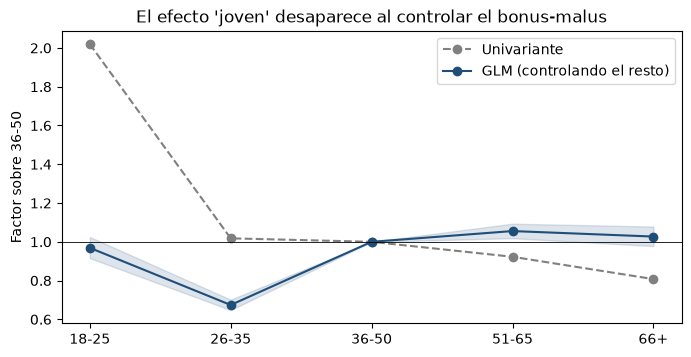

In [8]:
edad = relatividades[relatividades.index.str.startswith("tramo_edad")]
uni = univariante(df, "tramo_edad")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(uni.index.astype(str), uni["factor"] / uni.loc["36-50", "factor"], "o--", color="grey", label="Univariante")
niveles = ["18-25", "26-35", "36-50", "51-65", "66+"]
glm_f = [1.0 if n == "36-50" else edad.loc[f"tramo_edad = {n}", "factor"] for n in niveles]
lo = [1.0 if n == "36-50" else edad.loc[f"tramo_edad = {n}", "ic_inf"] for n in niveles]
hi = [1.0 if n == "36-50" else edad.loc[f"tramo_edad = {n}", "ic_sup"] for n in niveles]
ax.plot(niveles, glm_f, "o-", color="#1f4e79", label="GLM (controlando el resto)")
ax.fill_between(niveles, lo, hi, color="#1f4e79", alpha=0.15)
ax.axhline(1, color="k", lw=0.6)
ax.set_title("El efecto 'joven' desaparece al controlar el bonus-malus")
ax.set_ylabel("Factor sobre 36-50")
ax.legend()
plt.show()

### ✏️ Ejercicio 1.1
Según el GLM:
1. Guarda en `factor_zona_E` el factor de la zona E respecto a la zona C.
2. Calcula `frec_perfil`: la frecuencia esperada de un conductor de **26–35 años, BM 51–70, zona E** y el resto en el nivel base. Es decir: Intercept × factor(26–35) × factor(BM 51–70) × factor(zona E).

Pista: `relatividades.loc["zona = E", "factor"]`

In [9]:
factor_zona_E = relatividades.loc["zona = E", "factor"]
frec_perfil = (relatividades.loc["Intercept", "factor"] * relatividades.loc["tramo_edad = 26-35", "factor"]
               * relatividades.loc["tramo_bm = 51-70", "factor"] * factor_zona_E)
print(f"Factor zona E: {factor_zona_E:.3f} | Frecuencia del perfil: {frec_perfil:.4f}")

Factor zona E: 1.263 | Frecuencia del perfil: 0.0959


In [10]:
_perfil = pd.DataFrame({"tramo_edad": ["26-35"], "tramo_bm": ["51-70"], "zona": ["E"], "grupo_potencia": ["6-7"],
                        "grupo_antig": ["3-9"], "combustible": ["Diesel"]})
comprobar(lambda: frec_perfil, float(glm_frec.predict(_perfil, offset=np.zeros(1)).iloc[0]),
          "Multiplica el Intercept por los tres factores (todos en escala de factor, no de coeficiente)")

✅ ¡Correcto!


---
# Bloque 2 · GLM de coste medio (Gamma) y prima pura

### Tratamiento de los grandes siniestros
Los siniestros enormes son **impredecibles** a nivel de póliza (sesión 4) y distorsionan los factores. La práctica habitual:
1. **Limitar** cada siniestro a 100.000 € para modelizar.
2. Repartir el exceso como una **carga por grandes siniestros** proporcional para todos.

In [11]:
sin = cargar_siniestros_referencia()
sin["importe_limitado"] = sin["importe"].clip(upper=100_000)
carga_grandes = sin["importe"].sum() / sin["importe_limitado"].sum()
print(f"Carga por grandes siniestros: {carga_grandes:.3f} (el exceso sobre 100k supone un {carga_grandes - 1:.1%} adicional)")

limitado = sin.groupby("id_poliza")["importe_limitado"].sum()
train["coste_limitado"] = train["id_poliza"].map(limitado).fillna(0)

Carga por grandes siniestros: 1.215 (el exceso sobre 100k supone un 21.5% adicional)


### GLM Gamma
- **Respuesta:** coste medio por siniestro de cada póliza (solo pólizas con siniestro).
- **Familia Gamma con enlace log:** importes positivos y asimétricos, modelo multiplicativo.
- **Pesos:** número de siniestros (`var_weights`). Un coste medio de 5 siniestros es más fiable que el de uno.

> ⚠️ **Trampa clásica:** en `statsmodels`, la Gamma usa por defecto el enlace *inverso*, no el log. Hay que indicar `link=sm.families.links.Log()` o los coeficientes no son factores multiplicativos.

In [12]:
con_sin = train[train["n_siniestros"] > 0].copy()
con_sin["coste_medio"] = con_sin["coste_limitado"] / con_sin["n_siniestros"]

glm_sev = smf.glm("coste_medio ~ C(tramo_edad, Treatment('36-50')) + C(grupo_antig, Treatment('3-9')) + C(combustible)",
                  data=con_sin, family=sm.families.Gamma(link=sm.families.links.Log()),
                  var_weights=con_sin["n_siniestros"]).fit()
tabla_relatividades(glm_sev)

,factor,ic_inf,ic_sup,p_valor,significativo
Intercept,"1,757.205","1,612.928","1,914.388",0.000,sí
tramo_edad = 18-25,1.301,1.125,1.504,0.000,sí
tramo_edad = 26-35,1.105,0.991,1.232,0.072,no
tramo_edad = 51-65,0.993,0.897,1.098,0.888,no
tramo_edad = 66+,1.146,0.997,1.318,0.056,no
grupo_antig = 0-2,1.031,0.931,1.142,0.560,no
grupo_antig = 10+,0.967,0.884,1.057,0.458,no
combustible = Regular,1.012,0.936,1.095,0.761,no


**Aquí está la otra mitad de la historia:** los conductores de 18–25 años no tienen más siniestros (una vez descontado el bonus-malus), pero sus siniestros son **~30 % más caros** (y significativo). Además protagonizan los siniestros enormes, que el modelo trata aparte. **Este es el sobrecoste que la tarifa actual no recoge.**

### Prima pura del modelo

$$\text{Prima pura} = \text{Frecuencia} \times \text{Coste medio} \times \text{Carga grandes siniestros}$$

In [13]:
for d in (train, test):
    d["frec_modelo"] = glm_frec.predict(d, offset=np.zeros(len(d)))
    d["sev_modelo"] = glm_sev.predict(d)
    d["prima_pura_modelo"] = d["frec_modelo"] * d["sev_modelo"] * carga_grandes

# Calibración: que el total del modelo cuadre con el coste real de entrenamiento
calib = train["coste_siniestros"].sum() / (train["prima_pura_modelo"] * train["exposicion"]).sum()
for d in (train, test):
    d["prima_pura_modelo"] *= calib
print(f"Factor de calibración: {calib:.3f}")
test[["edad_conductor", "bonus_malus", "zona", "prima_anual", "prima_pura_modelo"]].head()

Factor de calibración: 0.984


,edad_conductor,bonus_malus,zona,prima_anual,prima_pura_modelo
4,46,50,B,144.870,102.358
8,33,68,C,275.430,166.039
17,32,56,A,223.040,138.319
25,33,100,D,440.910,220.458
27,59,50,C,159.420,97.218


---
# Bloque 3 · Segmentación con árboles de decisión

Un **árbol de decisión** busca automáticamente las preguntas sí/no que mejor separan pólizas de alta y baja frecuencia. Su gran ventaja para negocio es que **el resultado son reglas legibles**, que se pueden aplicar en Excel o en el sistema de suscripción.

Configuración clave:
- `criterion="poisson"`: el criterio adecuado para frecuencias.
- `sample_weight=exposicion` y respuesta = siniestros / exposición.
- `max_depth=3`: como mucho 8 segmentos, fáciles de explicar.
- `min_weight_fraction_leaf=0.03`: cada segmento con al menos el 3 % de la exposición, para que sea **creíble** (regla ±2/√N de la sesión 4).

In [14]:
from sklearn.tree import DecisionTreeRegressor, export_text, plot_tree

variables = ["edad_conductor", "bonus_malus", "antig_vehiculo", "potencia", "densidad"]
arbol = DecisionTreeRegressor(criterion="poisson", max_depth=3, min_weight_fraction_leaf=0.03, random_state=0)
arbol.fit(train[variables], train["n"] / train["exposicion"], sample_weight=train["exposicion"])
print(export_text(arbol, feature_names=variables, decimals=3))

|--- bonus_malus <= 57.500
|   |--- densidad <= 395.500
|   |   |--- antig_vehiculo <= 12.500
|   |   |   |--- value: [0.049]
|   |   |--- antig_vehiculo >  12.500
|   |   |   |--- value: [0.033]
|   |--- densidad >  395.500
|   |   |--- antig_vehiculo <= 14.500
|   |   |   |--- value: [0.066]
|   |   |--- antig_vehiculo >  14.500
|   |   |   |--- value: [0.043]
|--- bonus_malus >  57.500
|   |--- bonus_malus <= 90.500
|   |   |--- edad_conductor <= 36.500
|   |   |   |--- value: [0.084]
|   |   |--- edad_conductor >  36.500
|   |   |   |--- value: [0.146]
|   |--- bonus_malus >  90.500
|   |   |--- value: [0.216]



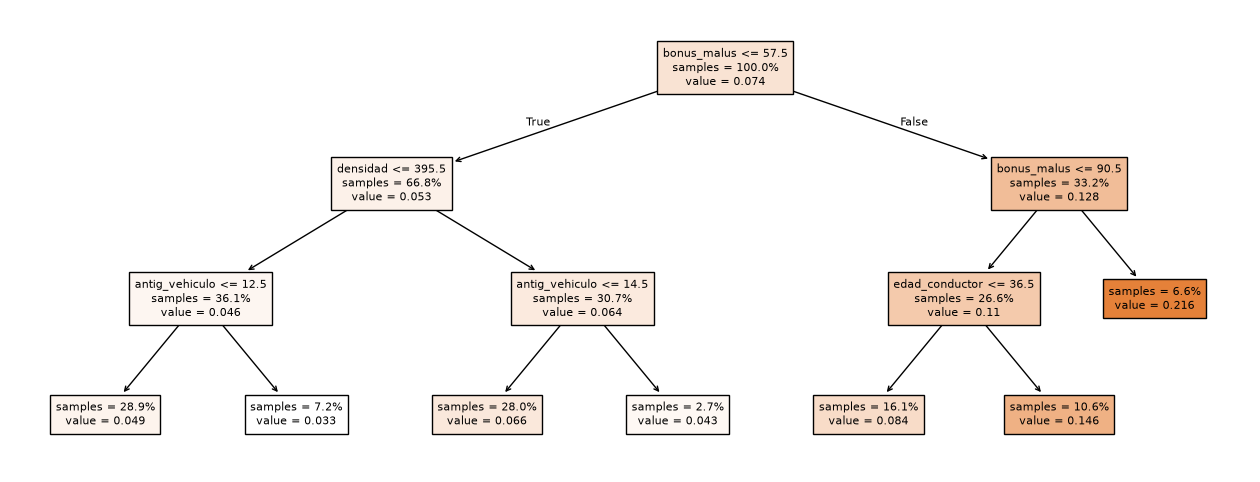

In [15]:
fig, ax = plt.subplots(figsize=(16, 6))
plot_tree(arbol, feature_names=variables, filled=True, impurity=False, proportion=True, precision=3, ax=ax, fontsize=8)
plt.show()

### Del árbol a la cuenta de resultados por segmento
`arbol.apply()` devuelve el segmento (hoja) de cada póliza. Con eso calculamos el **margen por segmento**: la información que necesita negocio.

In [16]:
df["segmento"] = arbol.apply(df[variables])
seg = df.groupby("segmento").agg(polizas=("id_poliza", "count"), exposicion=("exposicion", "sum"),
                                 n=("n", "sum"), primas=("prima_devengada", "sum"),
                                 siniestros=("coste_siniestros", "sum"), margen=("margen", "sum"))
seg["frecuencia"] = seg["n"] / seg["exposicion"]
seg["siniestralidad"] = seg["siniestros"] / seg["primas"]
seg["peso_primas"] = seg["primas"] / seg["primas"].sum()
seg.sort_values("frecuencia")

,polizas,exposicion,n,primas,siniestros,margen,frecuencia,siniestralidad,peso_primas
segmento,,,,,,,,,
4,48608,"32,886.932",1082,"5,166,813.184","1,771,146.740","1,984,977.037",0.033,0.343,0.062
7,18248,"11,198.115",504,"2,300,054.828","1,344,055.320","327,265.063",0.045,0.584,0.028
3,195599,"114,958.912",5641,"18,326,960.298","11,118,171.700","2,210,001.405",0.049,0.607,0.219
6,190019,"101,237.712",6669,"20,836,593.957","12,986,958.280","2,168,202.382",0.066,0.623,0.249
10,108912,"47,074.433",3949,"16,220,351.990","8,437,281.610","3,628,585.474",0.084,0.520,0.194
11,71675,"34,012.575",4918,"11,408,183.533","9,541,519.590","-1,255,503.611",0.145,0.836,0.137
12,44930,"16,964.392",3642,"9,276,775.985","14,710,083.260","-7,816,553.560",0.215,1.586,0.111


### ✏️ Ejercicio 3.1
1. Guarda en `segmento_peor` el número del segmento con **menor margen**.
2. Calcula `perdida_peor`: su margen (en €).
3. Mirando la salida de `export_text`, describe con palabras ese segmento (en un comentario).

In [17]:
segmento_peor = seg["margen"].idxmin()
perdida_peor = seg.loc[segmento_peor, "margen"]
# Descripción: conductores con bonus-malus > 90 (malus): frecuencia ~3 veces la media
print(f"Segmento {segmento_peor}: margen {perdida_peor:,.0f} €")

Segmento 12: margen -7,816,554 €


In [18]:
comprobar(lambda: perdida_peor, seg["margen"].min(), "seg['margen'].idxmin() da el segmento; .loc[..., 'margen'] su margen")

✅ ¡Correcto!


### Contraste: k-means (clustering no supervisado)
k-means agrupa pólizas **parecidas entre sí**, pero sin mirar si tienen siniestros. Es útil para describir la cartera (perfiles de cliente), no para segmentar por riesgo:

In [19]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

Z = StandardScaler().fit_transform(df[variables].assign(densidad=np.log(df["densidad"])))
df["cluster"] = KMeans(n_clusters=5, n_init=5, random_state=0).fit_predict(Z)
cl = df.groupby("cluster").agg(exposicion=("exposicion", "sum"), n=("n", "sum"),
                               primas=("prima_devengada", "sum"), siniestros=("coste_siniestros", "sum"))
cl["frecuencia"] = cl["n"] / cl["exposicion"]
cl["siniestralidad"] = cl["siniestros"] / cl["primas"]
print("Diferencia de frecuencia entre el mejor y el peor grupo:")
print(f"  árbol:   {seg['frecuencia'].max() / seg['frecuencia'].min():.1f} veces")
print(f"  k-means: {cl['frecuencia'].max() / cl['frecuencia'].min():.1f} veces")

Diferencia de frecuencia entre el mejor y el peor grupo:
  árbol:   6.5 veces
  k-means: 2.6 veces


El árbol, al estar **guiado por los siniestros**, separa mucho mejor el riesgo.

---
# Bloque 4 · Validación y simulación de impacto

### 4.1 ¿Ordena bien el riesgo? Curva de lift (en test)
Ordenamos las pólizas de test por la prima pura que predice el modelo, las agrupamos en 10 grupos de igual exposición y comparamos lo **predicho** con lo **observado**.

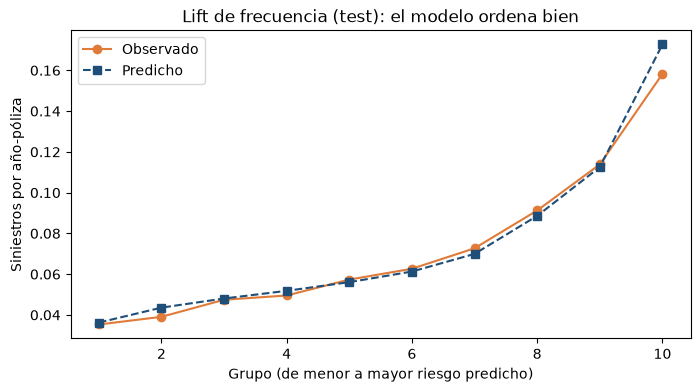

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))
lift = curva_lift(test["n"] / test["exposicion"], test["frec_modelo"],
                  test["exposicion"], ax=ax, titulo="Lift de frecuencia (test): el modelo ordena bien")
ax.set_ylabel("Siniestros por año-póliza")
plt.show()

### 4.2 Gini: el modelo frente a la tarifa actual
El **índice de Gini** mide cuánto concentra el modelo los siniestros en las pólizas que señala como más arriesgadas (0 = azar). Comparamos el modelo con la **tarifa actual**, usando su prima como predictor.

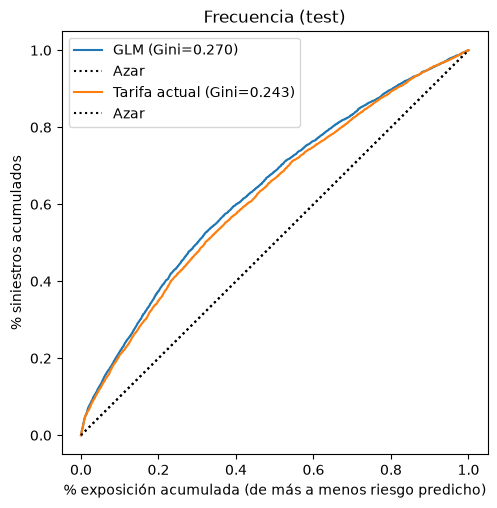

In [21]:
y_test = test["n"] / test["exposicion"]
fig, ax = plt.subplots(figsize=(5.5, 5.5))
curva_lorenz(y_test, test["frec_modelo"], test["exposicion"], ax=ax, etiqueta="GLM")
curva_lorenz(y_test, test["prima_anual"], test["exposicion"], ax=ax, etiqueta="Tarifa actual")
ax.set_title("Frecuencia (test)")
plt.show()

El GLM ordena mejor que la tarifa actual, aunque la mejora es moderada: la tarifa actual ya usa los dos factores más potentes (bonus-malus y zona). **Es lo habitual en la vida real**: las mejoras de tarifa se ganan punto a punto.

### 4.3 Doble lift: ¿dónde está mal cobrada la tarifa actual?
Para cada póliza: **ratio = prima modelo / prima actual**. Si el modelo tiene razón, donde el ratio es alto (el modelo cobraría más), la siniestralidad *real* con la tarifa actual debería ser alta.

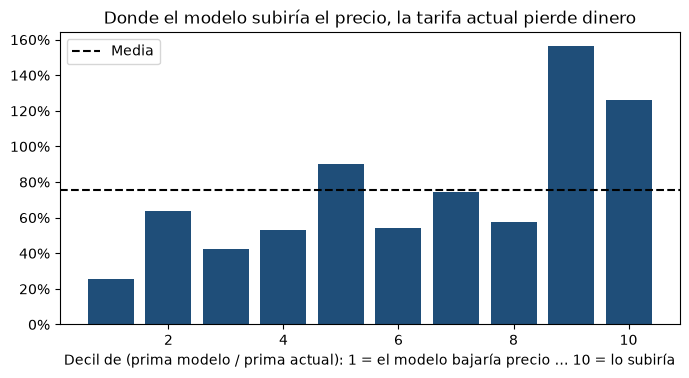

,ratio_medio,primas,siniestros,siniestralidad_tarifa_actual
decil,,,,
1,0.706,"1,855,406.815","476,794.270",0.257
2,0.803,"1,681,274.081","1,071,717.160",0.637
3,0.864,"1,610,073.028","680,040.580",0.422
4,0.913,"1,603,495.088","851,202.750",0.531
5,0.960,"1,570,648.828","1,415,475.200",0.901
6,1.010,"1,548,276.309","835,449.320",0.540
7,1.061,"1,546,715.718","1,149,774.050",0.743
8,1.120,"1,578,319.054","909,515.080",0.576
9,1.203,"1,689,883.388","2,645,274.290",1.565


In [22]:
test["prima_modelo"] = test["prima_pura_modelo"] / 0.70     # mismo objetivo de siniestralidad que la tarifa actual
test["ratio_modelo_actual"] = test["prima_modelo"] / test["prima_anual"]
test["decil"] = pd.qcut(test["ratio_modelo_actual"], 10, labels=False) + 1
dl = test.groupby("decil").agg(ratio_medio=("ratio_modelo_actual", "mean"), primas=("prima_devengada", "sum"),
                              siniestros=("coste_siniestros", "sum"))
dl["siniestralidad_tarifa_actual"] = dl["siniestros"] / dl["primas"]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(dl.index, dl["siniestralidad_tarifa_actual"], color="#1f4e79")
ax.axhline(test["coste_siniestros"].sum() / test["prima_devengada"].sum(), color="k", ls="--", label="Media")
ax.set_xlabel("Decil de (prima modelo / prima actual): 1 = el modelo bajaría precio … 10 = lo subiría")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Donde el modelo subiría el precio, la tarifa actual pierde dinero")
ax.legend()
plt.show()
dl

### 4.4 Simulación: tarifa nueva **neutral en ingresos**
Redistribuimos la **misma prima total** según el modelo, limitando los cambios a ±25 % por póliza (para no perder clientes de golpe). ¿Cómo queda la siniestralidad por segmento?

> Supuesto simplificador: ningún cliente se da de baja por el cambio de precio. En la realidad hay que modelizar la **elasticidad**, que es otro proyecto.

In [23]:
sim = test.copy()
cambio = sim["ratio_modelo_actual"].clip(0.75, 1.25)
sim["prima_nueva_dev"] = sim["prima_devengada"] * cambio
sim["prima_nueva_dev"] *= sim["prima_devengada"].sum() / sim["prima_nueva_dev"].sum()    # neutral en ingresos

sim["segmento"] = arbol.apply(sim[variables])
comp = sim.groupby("segmento").agg(primas_actual=("prima_devengada", "sum"), primas_nueva=("prima_nueva_dev", "sum"),
                                   siniestros=("coste_siniestros", "sum"))
comp["siniestralidad_actual"] = comp["siniestros"] / comp["primas_actual"]
comp["siniestralidad_nueva"] = comp["siniestros"] / comp["primas_nueva"]
comp["cambio_precio"] = comp["primas_nueva"] / comp["primas_actual"] - 1
comp.style.format({"primas_actual": "{:,.0f}", "primas_nueva": "{:,.0f}", "siniestros": "{:,.0f}",
                   "siniestralidad_actual": "{:.0%}", "siniestralidad_nueva": "{:.0%}", "cambio_precio": "{:+.1%}"})

,primas_actual,primas_nueva,siniestros,siniestralidad_actual,siniestralidad_nueva,cambio_precio
segmento,,,,,,
3,"3,640,347","3,658,176","2,385,317",66%,65%,+0.5%
4,"1,024,415","907,557","528,485",52%,58%,-11.4%
6,"4,179,985","4,144,869","2,907,670",70%,70%,-0.8%
7,"481,967","429,955","262,376",54%,61%,-10.8%
10,"3,239,411","3,051,197","1,252,192",39%,41%,-5.8%
11,"2,288,800","2,546,244","2,566,732",112%,101%,+11.2%
12,"1,892,939","2,009,865","2,736,519",145%,136%,+6.2%


### ✏️ Ejercicio 4.1
Calcula la **dispersión de la siniestralidad entre segmentos** (desviación típica ponderada por primas) antes y después del cambio de tarifa, en `disp_actual` y `disp_nueva`. Una tarifa más justa debería **reducirla**.

Pista: `np.sqrt(np.average((x - media)**2, weights=w))`, donde `media = np.average(x, weights=w)`.

In [24]:
def disp_ponderada(x, w):
    media = np.average(x, weights=w)
    return np.sqrt(np.average((x - media) ** 2, weights=w))

disp_actual = disp_ponderada(comp["siniestralidad_actual"], comp["primas_actual"])
disp_nueva = disp_ponderada(comp["siniestralidad_nueva"], comp["primas_nueva"])
print(f"Dispersión actual: {disp_actual:.1%} → nueva: {disp_nueva:.1%}")

Dispersión actual: 32.6% → nueva: 28.4%


In [25]:
def _dp(x, w):
    m = np.average(x, weights=w)
    return np.sqrt(np.average((x - m) ** 2, weights=w))
comprobar(lambda: (round(disp_actual, 6), round(disp_nueva, 6)),
          (round(_dp(comp["siniestralidad_actual"], comp["primas_actual"]), 6),
           round(_dp(comp["siniestralidad_nueva"], comp["primas_nueva"]), 6)),
          "Pondera cada segmento por sus primas (actuales o nuevas, respectivamente)")

✅ ¡Correcto!


---
## Resumen de la sesión (y del curso)
- El **análisis univariante engaña** cuando las variables están relacionadas (edad ↔ bonus-malus). El GLM separa los efectos.
- Los **factores** `exp(β)` del GLM son una tabla multiplicativa, el mismo lenguaje que una tarifa en Excel.
- Frecuencia (Poisson) y coste medio (Gamma, con grandes siniestros aparte) cuentan **historias distintas**: los jóvenes no tienen más siniestros a igual bonus-malus, pero sí siniestros más caros.
- Un **árbol de decisión** da segmentos con reglas legibles y su margen asociado.
- Valida siempre en **datos no vistos** (test): lift, Gini y **doble lift contra la tarifa actual**.
- El objetivo de negocio no es "el mejor modelo", sino **tomar mejores decisiones de precio y de mix**.

### ¿Y ahora qué?
- Notebooks complementarios: **C1** (grandes volúmenes y SQL) y **C2** (reservas e IBNR).
- Para profundizar: *CAS Monograph 5 – GLMs for Insurance Rating* (Goldburd et al.) y los tutoriales de [actuarialdatascience.org](https://www.actuarialdatascience.org).
- Reto: aplica el patrón de la sesión 3 (`src/` + `scripts/` + `config/`) a un informe real que hoy hagas a mano.